In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem
from math import factorial
import pickle

C:\Users\User\anaconda3\Lib\site-packages\torch\__init__.py:1275: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


In [2]:
b0 = 1
b1 = 5e-1
b2 = 1e-1
sigma0 = 5e-1
sigma2 = 1e-1

params = {'b0': b0, 'b1': b1, 'b2': b2,
          'sigma0': sigma0, 'sigma2': sigma2, 'X0': 10, 
          'A': 0, 'B': 1, 'C': 0, 'D':0, 'E':1, 'G': 0,
          'T': 0.10, 'Nt': 1_000}

env = lqproblem.environment(**params)

In [3]:
np.random.seed(456)
dim = 2
order = 3

with open('W_sig_1.pkl', 'rb') as f:
    W_sig = pickle.load(f)
    f.close()

# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()
    
#env = lqproblem.environment(**params)
optimiser_1 = optimiser_lqproblem.Optimiser(env, W_sig, order = order)
#F = ta.sig_to_tensor(F, env.dim, order)
#optimiser_1.F = F

In [4]:
np.random.seed(456)
max_order_x = 8
max_order_fn = 6
n_epochs = 10
lr = 5

optimiser_1.train_sgd(n_epochs, lr = lr, max_order_x = max_order_x, max_order_fn = max_order_fn, truncate_fn = True, method='SGD')

F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = order)

[101.88748925]: 100%|██████████| 10/10 [00:32<00:00,  3.24s/it]


In [5]:
F = optimiser_1.F

strag_sig = lqproblem.sig_strag_dot(F, order = order)

In [6]:
# # F = optimiser_1.F

# # strag_sig = lqproblem.sig_strag_dot(F, order = order)

# with open('F_optimised_problem2.pkl', 'wb') as f:
#     pickle.dump(F.flatten(), f)
#     f.close()

In [7]:
np.random.seed(123)

nsims = 100

env.simulate(nsims, strag_sig, max_order_x)

C:\Users\User\Documents\GitHub\optimal-control-with-signatures\notebooks\../src\lqproblem.py:134: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  strag[nsim] = F.dot(W_sig)


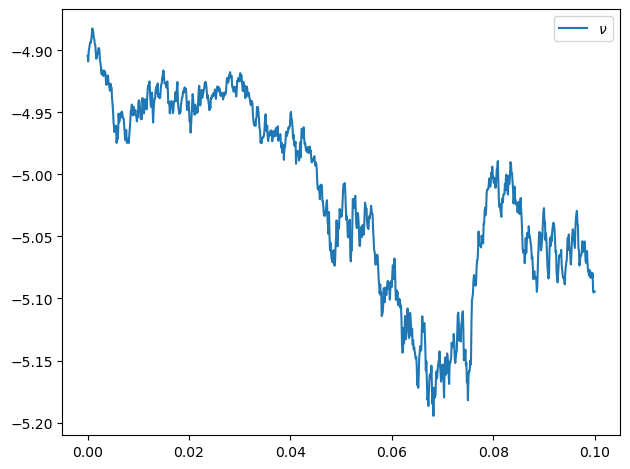

In [8]:
nsim = 1

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
print(f'Performance criterion\nSig: {env.performance.mean()}')

Performance criterion
Sig: 102.33007726863926


In [10]:
optimiser_1.value_fn(F, max_order_x = max_order_x, truncate_fn = True, max_order_fn = max_order_fn)

tensor([101.8874], grad_fn=<AddBackward0>)

In [11]:
# # f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# # f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# # f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

# max_order = max(max_order_x, max_order_fn)

# nsim = 1

# LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_x)
# p_perf = optimiser_1.p_perf
# p_perf_run = optimiser_1.p_perf_run

# f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
# f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

# X_sig = np.zeros((env.Nt+1,))
# perf_hist = np.zeros((env.Nt+1,))

# W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

# X_sig[0] = f_x_sig(env,W_sig,dim,0)
# perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# # S_sig = f_s_sig(env)
# # alpha_hat_sig = f_alpha_sig(env)
# # perf_hist = f_perf_crit(env)

# for it in range(1,env.Nt+1):
#     path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
#     W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
#     X_sig[it] = f_x_sig(env,W_sig,dim,it)
#     perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
#     #S_sig[it,:] = strag_sig(env,it)

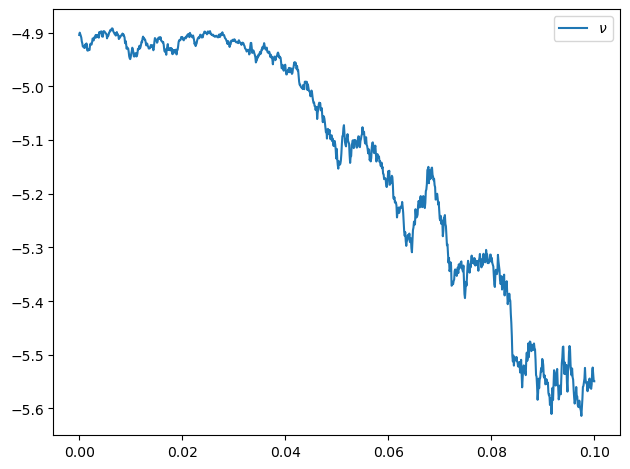

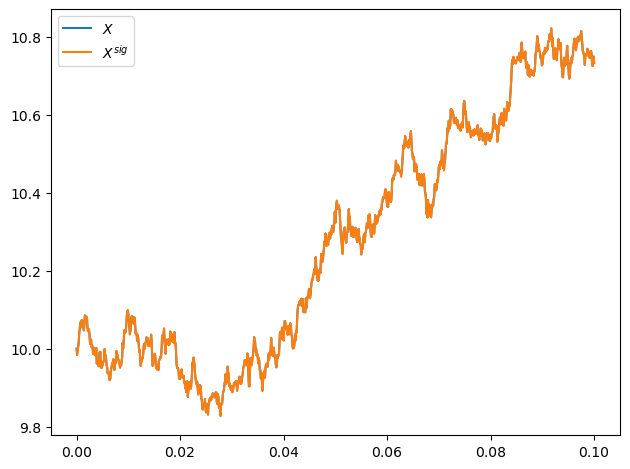

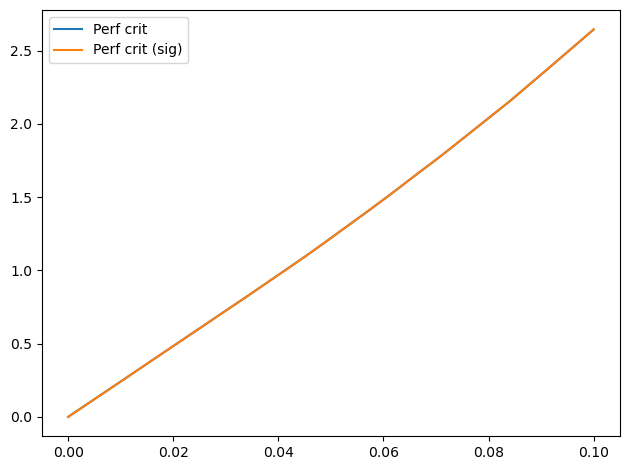

In [12]:
nsim = 0

max_order = max(max_order_x, max_order_fn)

LF = optimiser_1.LF(optimiser_1.F, max_order = max_order_x)
p_perf = optimiser_1.p_perf
p_perf_run = optimiser_1.p_perf_run

f_x_sig = lqproblem.sig_strag_dot_2(LF, order = max_order_x)
f_perf_crit_run = lqproblem.sig_strag_dot_2(p_perf_run, order = max_order_fn)

X_sig = np.zeros((env.Nt+1,))
perf_hist = np.zeros((env.Nt+1,))

W_sig = np.zeros(((env.dim**(max_order+1) - env.dim)//(env.dim - 1),))

X_sig[0] = f_x_sig(env,W_sig,dim,0)
perf_hist[0] = f_perf_crit_run(env,W_sig,dim,0)

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(1,env.Nt+1):
    path_increment = np.array([env.timesteps[it]-env.timesteps[it-1], env.W[it,nsim]-env.W[it-1,nsim]])
    W_sig[:] = iisignature.sigjoin(W_sig[:], path_increment, max_order)
    X_sig[it] = f_x_sig(env,W_sig,dim,it)
    perf_hist[it] = f_perf_crit_run(env,W_sig,dim,it)
    #S_sig[it,:] = strag_sig(env,it)

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.X[:,nsim], label=r'$X$')
plt.plot(env.timesteps, X_sig[:], label=r'$X^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()

In [14]:
LF.order

8